# Mouse TEa Distance Calculation

Calculate **signed** Euclidean distance from soma locations to the TEa structure border in the CCF.

**CCF Coordinate System**: PIR (Posterior-Inferior-Right)
- X = Posterior-Anterior (increasing X = posterior)
- Y = Inferior-Superior (increasing Y = ventral)
- Z = Right-Left (increasing Z = right)

**Distance Convention**:
- **Negative distance**: Cell is inside TEa
- **Positive distance**: Cell is outside TEa
- **Zero distance**: Cell is on the border of TEa

**Hemisphere Split**: Based on Z-axis (left-right axis in PIR)

In [17]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import nrrd
from scipy.ndimage import distance_transform_edt, binary_erosion
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Parameters
soma_pins_path = Path('/root/capsule/data/mouse_TEa/temp-mouse_patchseq_soma_pins/soma_pins.csv')

output_dir = Path('/root/capsule/scratch/') / '20260807' / 'mouse_TEa_distances'
os.makedirs(output_dir, exist_ok=True)


In [3]:
# Load soma pins data
soma_df = pd.read_csv(soma_pins_path)
print(f"Loaded {len(soma_df)} cells")
soma_df.head()

Loaded 5658 cells


,cell_specimen_id,slide_specimen_id,specimen_name,x,y,z,structure_id,structure_acronym
0,1.254218e+09,1254192732,C57BL6J-667412.13.10.01,6725.000000,3807.984131,6180.958496,362,MD
1,1.254225e+09,1254192732,C57BL6J-667412.13.10.02,6725.000000,3685.511719,6276.875000,362,MD
2,1.254238e+09,1254192732,C57BL6J-667412.13.10.03,6725.000000,3607.036133,6302.043457,362,MD
3,1.190345e+09,1189282403,C57BL6J-634112.05.01.01,8846.905344,1215.824000,2322.970703,821,VISp2/3
4,1.190354e+09,1189282403,C57BL6J-634112.05.01.02,8698.307617,1624.090698,2576.191895,778,VISp5


In [4]:
# Load CCF annotation volume
annotation, header = nrrd.read('/root/capsule/data/ccf/annotation_10.nrrd')
print(f"Annotation shape: {annotation.shape}")
print(f"Annotation dtype: {annotation.dtype}")

Annotation shape: (1320, 800, 1140)
Annotation dtype: uint32


In [5]:
# Find all TEa substructures
# TEa consists of multiple layers: TEa1, TEa2/3, TEa4, TEa5, TEa6a, TEa6b
# We need to find their structure IDs from the soma_df

tea_acronyms = ['TEa1', 'TEa2/3', 'TEa5', 'TEa6a', 'TEa6b', 'TEa4']

# Get unique structure IDs that match TEa acronyms
if 'structure_acronym' in soma_df.columns:
    tea_structures = soma_df[soma_df['structure_acronym'].isin(tea_acronyms)]
    tea_structure_ids = tea_structures['structure_id'].unique()
    print(f"Found TEa structure IDs: {tea_structure_ids}")
    print(f"Structure acronyms: {tea_structures[['structure_id', 'structure_acronym']].drop_duplicates().values}")
else:
    # Fallback to common TEa structure IDs if we can't find them in the data
    print("Warning: structure_acronym not found in data, using common TEa IDs")
    tea_structure_ids = [541]  # This might need to be adjusted

print(f"\nNumber of TEa substructures: {len(tea_structure_ids)}")

Found TEa structure IDs: [  97 1127  289  729  786  234]
Structure acronyms: [[97 'TEa1']
 [1127 'TEa2/3']
 [289 'TEa5']
 [729 'TEa6a']
 [786 'TEa6b']
 [234 'TEa4']]

Number of TEa substructures: 6


In [6]:
# Create combined TEa mask from all substructures
tea_mask = np.zeros_like(annotation, dtype=bool)

for tea_id in tea_structure_ids:
    tea_mask |= (annotation == tea_id)

print(f"Total TEa voxels (all substructures combined): {tea_mask.sum()}")
print(f"TEa structures included: {tea_structure_ids}")

Total TEa voxels (all substructures combined): 3102282
TEa structures included: [  97 1127  289  729  786  234]


In [7]:
# The CCF is in PIR coordinates:
# X = Posterior (increasing x = posterior)
# Y = Inferior (increasing y = ventral/down)  
# Z = Right (increasing z = right)
# Therefore, the LEFT-RIGHT axis is Z, not X!

# Determine the midline z-coordinate (left-right axis)
midline_z = annotation.shape[2] // 2
print(f"Midline z-coordinate (left-right axis): {midline_z}")
print(f"Annotation dimensions (X=P-A, Y=I-S, Z=R-L): {annotation.shape}")

# CCF coordinates are in microns with 10 micron resolution
# Voxel coordinates = CCF coordinates / 10
resolution = 10  # microns per voxel

Midline z-coordinate (left-right axis): 570
Annotation dimensions (X=P-A, Y=I-S, Z=R-L): (1320, 800, 1140)


In [8]:
# Debug: Check the coordinate system and TEa distribution
print("=== DEBUGGING COORDINATE SYSTEM ===\n")

# Check soma z-coordinate distribution (left-right axis)
print("Soma Z coordinates (microns) [LEFT-RIGHT axis]:")
print(f"  Min: {soma_df['z'].min()}")
print(f"  Max: {soma_df['z'].max()}")
print(f"  Mean: {soma_df['z'].mean()}")
print(f"  Median: {soma_df['z'].median()}")

print(f"\nAnnotation shape (voxels): {annotation.shape}")
print(f"Annotation in microns: ({annotation.shape[0]*resolution}, {annotation.shape[1]*resolution}, {annotation.shape[2]*resolution})")

# Check where TEa voxels are located
tea_coords = np.array(np.where(tea_mask)).T
if len(tea_coords) > 0:
    print(f"\nTEa voxel coordinates (in voxels):")
    print(f"  X range (P-A): {tea_coords[:, 0].min()} to {tea_coords[:, 0].max()}")
    print(f"  Y range (I-S): {tea_coords[:, 1].min()} to {tea_coords[:, 1].max()}")
    print(f"  Z range (R-L): {tea_coords[:, 2].min()} to {tea_coords[:, 2].max()}")
    
    print(f"\nTEa coordinates (in microns):")
    print(f"  X range (P-A): {tea_coords[:, 0].min()*resolution} to {tea_coords[:, 0].max()*resolution}")
    print(f"  Y range (I-S): {tea_coords[:, 1].min()*resolution} to {tea_coords[:, 1].max()*resolution}")
    print(f"  Z range (R-L): {tea_coords[:, 2].min()*resolution} to {tea_coords[:, 2].max()*resolution}")
    
    print(f"\nMidline calculation:")
    print(f"  Midline voxel (Z-axis): {midline_z}")
    print(f"  Midline microns: {midline_z * resolution}")
    
    print(f"\nHemisphere split preview:")
    print(f"  Left will be: z < {midline_z} voxels (< {midline_z*resolution} microns)")
    print(f"  Right will be: z >= {midline_z} voxels (>= {midline_z*resolution} microns)")
else:
    print("\nWARNING: No TEa voxels found!")

=== DEBUGGING COORDINATE SYSTEM ===

Soma Z coordinates (microns) [LEFT-RIGHT axis]:
  Min: 597.591552734375
  Max: 10717.53520517555
  Mean: 5615.678240744033
  Median: 5481.341552734375

Annotation shape (voxels): (1320, 800, 1140)
Annotation in microns: (13200, 8000, 11400)

TEa voxel coordinates (in voxels):
  X range (P-A): 694 to 948
  Y range (I-S): 174 to 445
  Z range (R-L): 53 to 1086

TEa coordinates (in microns):
  X range (P-A): 6940 to 9480
  Y range (I-S): 1740 to 4450
  Z range (R-L): 530 to 10860

Midline calculation:
  Midline voxel (Z-axis): 570
  Midline microns: 5700

Hemisphere split preview:
  Left will be: z < 570 voxels (< 5700 microns)
  Right will be: z >= 570 voxels (>= 5700 microns)


In [9]:
# Split TEa into left and right hemispheres along Z-axis
tea_mask_left = tea_mask.copy()
tea_mask_left[:, :, midline_z:] = False  # Left hemisphere: z < midline

tea_mask_right = tea_mask.copy()
tea_mask_right[:, :, :midline_z] = False  # Right hemisphere: z >= midline

In [10]:
# Check hemisphere split results
print(f"TEa voxels in left hemisphere (z < {midline_z}): {tea_mask_left.sum()}")
print(f"TEa voxels in right hemisphere (z >= {midline_z}): {tea_mask_right.sum()}")

if tea_mask_left.sum() == 0:
    print("\n⚠️ WARNING: No TEa found in left hemisphere!")
    print("This suggests the hemisphere splitting logic may need adjustment.")
    
if tea_mask_right.sum() == 0:
    print("\n⚠️ WARNING: No TEa found in right hemisphere!")
    print("This suggests the hemisphere splitting logic may need adjustment.")

TEa voxels in left hemisphere (z < 570): 1551141
TEa voxels in right hemisphere (z >= 570): 1551141


In [11]:
# Get border voxels for TEa in each hemisphere
# Border voxels are those that have at least one non-TEa neighbor
def get_border_voxels(mask):
    """Get voxels at the border of a structure"""
    eroded = binary_erosion(mask)
    border = mask & ~eroded
    return border

tea_border_left = get_border_voxels(tea_mask_left)
tea_border_right = get_border_voxels(tea_mask_right)

print(f"TEa border voxels in left hemisphere: {tea_border_left.sum()}")
print(f"TEa border voxels in right hemisphere: {tea_border_right.sum()}")

TEa border voxels in left hemisphere: 103051
TEa border voxels in right hemisphere: 103051


In [12]:
# Get coordinates of border voxels in each hemisphere
tea_border_coords_left = np.array(np.where(tea_border_left)).T
tea_border_coords_right = np.array(np.where(tea_border_right)).T

# Convert to CCF micron coordinates
tea_border_coords_left_microns = tea_border_coords_left * resolution
tea_border_coords_right_microns = tea_border_coords_right * resolution

print(f"Left hemisphere border coordinates shape: {tea_border_coords_left_microns.shape}")
print(f"Right hemisphere border coordinates shape: {tea_border_coords_right_microns.shape}")

Left hemisphere border coordinates shape: (103051, 3)
Right hemisphere border coordinates shape: (103051, 3)


In [13]:
# Build KD-trees for efficient nearest neighbor search
tree_left = cKDTree(tea_border_coords_left_microns)
tree_right = cKDTree(tea_border_coords_right_microns)
print("KD-trees built")

KD-trees built


In [14]:
# Calculate SIGNED distance to TEa border for each soma
# Negative distance = inside TEa, Positive distance = outside TEa
distances = []

for idx, row in soma_df.iterrows():
    soma_pos = np.array([row['x'], row['y'], row['z']])
    
    # Convert to voxel coordinates for checking if inside TEa
    soma_voxel = (soma_pos / resolution).astype(int)
    
    # Ensure coordinates are within bounds
    if (soma_voxel[0] < 0 or soma_voxel[0] >= annotation.shape[0] or
        soma_voxel[1] < 0 or soma_voxel[1] >= annotation.shape[1] or
        soma_voxel[2] < 0 or soma_voxel[2] >= annotation.shape[2]):
        distances.append(np.nan)
        continue
    
    # Determine hemisphere based on Z coordinate (left-right axis in PIR)
    midline_microns = midline_z * resolution
    is_left_hemisphere = soma_pos[2] < midline_microns  # Z < midline = left
    
    # Check if soma is inside TEa in its hemisphere
    if is_left_hemisphere:
        is_inside_tea = tea_mask_left[soma_voxel[0], soma_voxel[1], soma_voxel[2]]
        hemisphere_mask = tea_mask_left
        border_coords = tea_border_coords_left_microns
        tree = tree_left
    else:
        is_inside_tea = tea_mask_right[soma_voxel[0], soma_voxel[1], soma_voxel[2]]
        hemisphere_mask = tea_mask_right
        border_coords = tea_border_coords_right_microns
        tree = tree_right
    
    # Query the appropriate KD-tree for distance to border
    if len(border_coords) > 0:
        distance, _ = tree.query(soma_pos)
        
        # If inside TEa, make distance negative
        if is_inside_tea:
            distance = -distance
    else:
        distance = np.nan
    
    distances.append(distance)

# Add distances to dataframe
soma_df['distance_to_TEa_um'] = distances
print(f"\nDistance statistics (microns):")
print(soma_df['distance_to_TEa_um'].describe())
print(f"\nCells inside TEa (distance < 0): {(soma_df['distance_to_TEa_um'] < 0).sum()}")
print(f"Cells outside TEa (distance > 0): {(soma_df['distance_to_TEa_um'] > 0).sum()}")


Distance statistics (microns):
count    5658.000000
mean     2922.011378
std      1168.102015
min      -238.573437
25%      2191.364906
50%      3178.777266
75%      3777.264006
max      6134.059237
Name: distance_to_TEa_um, dtype: float64

Cells inside TEa (distance < 0): 60
Cells outside TEa (distance > 0): 5598


In [15]:
# Save updated CSV
output_path = os.path.join(output_dir, 'soma_pins_with_distances.csv')
soma_df.to_csv(output_path, index=False)
print(f"Saved results to: {output_path}")

Saved results to: /root/capsule/scratch/20260807/mouse_TEa_distances/soma_pins_with_distances.csv


### Visual inspection

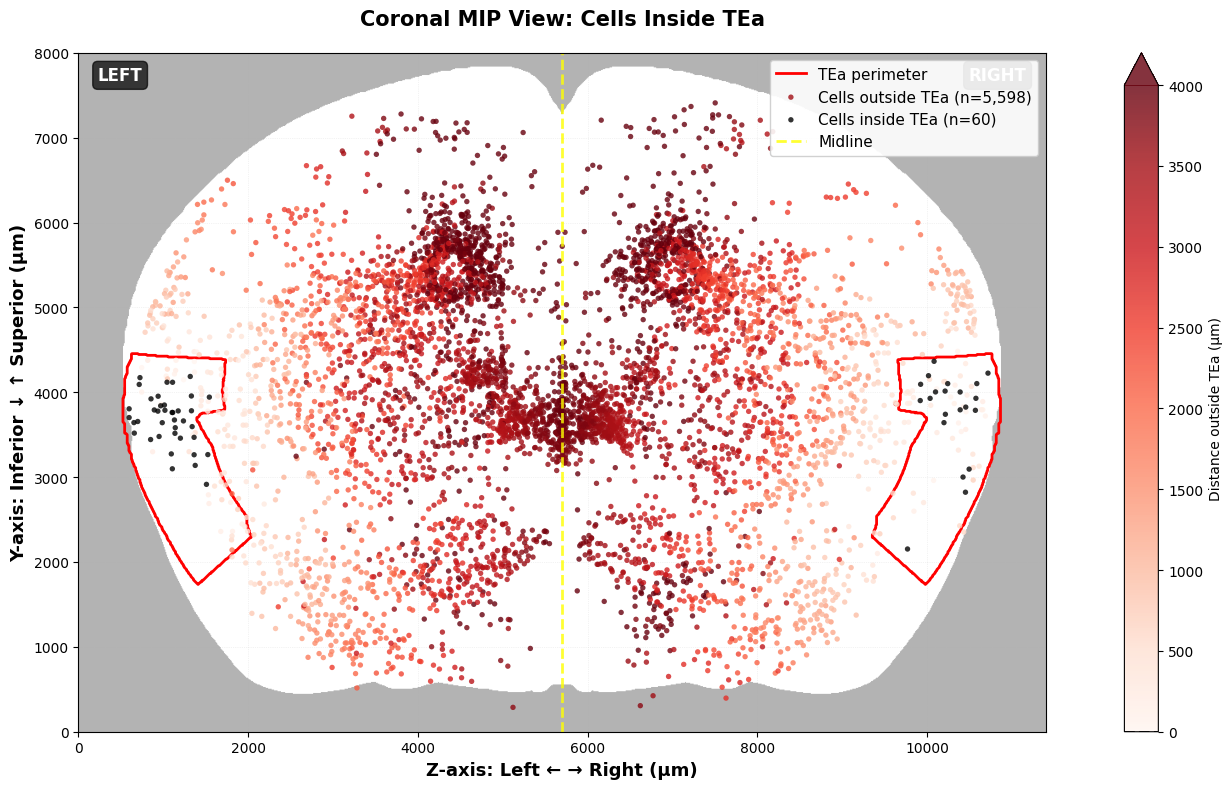

Saved coronal view to: /root/capsule/scratch/20260807/mouse_TEa_distances/coronal_view_distance_to_TEa.png


In [18]:
fig, ax = plt.subplots(figsize=(16, 8))

# Coronal maximum-intensity projection of the brain
mip_coronal = np.max(annotation > 0, axis=0).astype(float)

ax.imshow(
    mip_coronal,
    cmap='gray',
    alpha=0.3,
    origin='upper',
    extent=[
        0,
        annotation.shape[2] * resolution,
        0,
        annotation.shape[1] * resolution,
    ],
    aspect='equal',
)

# Project the filled TEa masks into the coronal Y–Z plane.
# Replace tea_mask_left/right with the names of your filled TEa masks
# if they are named differently.
tea_coronal = np.any(
    tea_mask_left | tea_mask_right,
    axis=0,
)

# Coordinate arrays in microns
z_um = np.arange(annotation.shape[2]) * resolution
y_um = np.arange(annotation.shape[1]) * resolution

# Draw only the perimeter of the projected TEa region
ax.contour(
    z_um,
    y_um,
    tea_coronal.astype(float),
    levels=[0.5],
    colors='red',
    linewidths=2,
)

# Plot only cells inside TEa: negative signed distance
from matplotlib.colors import Normalize

# Separate cells inside and outside TEa
inside_tea = soma_df[soma_df['distance_to_TEa_um'] < 0]
outside_tea = soma_df[soma_df['distance_to_TEa_um'] >= 0]

# Scale colors from the TEa border to 4,000 µm away
norm = Normalize(vmin=0, vmax=4000, clip=True)

# Plot outside cells colored by distance
outside_scatter = ax.scatter(
    outside_tea['z'],
    outside_tea['y'],
    c=outside_tea['distance_to_TEa_um'],
    cmap='Reds',
    norm=norm,
    s=15,
    alpha=0.8,
    edgecolors='none',
    label=f'Cells outside TEa (n={len(outside_tea):,})',
    zorder=2,
)

# Plot inside cells as black dots
ax.scatter(
    inside_tea['z'],
    inside_tea['y'],
    c='black',
    s=15,
    alpha=0.8,
    edgecolors='none',
    label=f'Cells inside TEa (n={len(inside_tea):,})',
    zorder=3,
)

# Colorbar applies only to cells outside TEa
cbar = fig.colorbar(
    outside_scatter,
    ax=ax,
    label='Distance outside TEa (μm)',
    extend='max',
)

# Mark the border value on the colorbar
cbar.ax.axhline(
    0,
    color='black',
    linewidth=2,
    linestyle='--',
)

# Midline
midline_microns = midline_z * resolution
ax.axvline(
    midline_microns,
    color='yellow',
    linewidth=2,
    linestyle='--',
    alpha=0.8,
    label='Midline',
)

ax.set_xlabel('Z-axis: Left ← → Right (μm)', fontsize=13, fontweight='bold')
ax.set_ylabel('Y-axis: Inferior ↓ ↑ Superior (μm)', fontsize=13, fontweight='bold')
ax.set_title(
    'Coronal MIP View: Cells Inside TEa',
    fontsize=15,
    fontweight='bold',
    pad=20,
)

ax.set_aspect('equal')
ax.set_xlim(0, annotation.shape[2] * resolution)
ax.set_ylim(0, annotation.shape[1] * resolution)

# Add a legend entry for the contour
tea_handle = plt.Line2D(
    [0],
    [0],
    color='red',
    linewidth=2,
    label='TEa perimeter',
)

handles, labels = ax.get_legend_handles_labels()
ax.legend(
    [tea_handle] + handles,
    ['TEa perimeter'] + labels,
    loc='upper right',
    fontsize=11,
    framealpha=0.9,
)

ax.grid(True, alpha=0.3, linestyle=':', linewidth=0.5)

ax.text(
    0.02, 0.98, 'LEFT',
    transform=ax.transAxes,
    fontsize=12,
    fontweight='bold',
    va='top',
    ha='left',
    color='white',
    bbox=dict(boxstyle='round', facecolor='black', alpha=0.7),
)

ax.text(
    0.98, 0.98, 'RIGHT',
    transform=ax.transAxes,
    fontsize=12,
    fontweight='bold',
    va='top',
    ha='right',
    color='white',
    bbox=dict(boxstyle='round', facecolor='black', alpha=0.7),
)

plt.tight_layout()

output_path = os.path.join(output_dir, 'coronal_view_distance_to_TEa.png')
plt.savefig(
    output_path,
    dpi=300,
    bbox_inches='tight',
    facecolor='white',
)
plt.show()

print(f'Saved coronal view to: {output_path}')

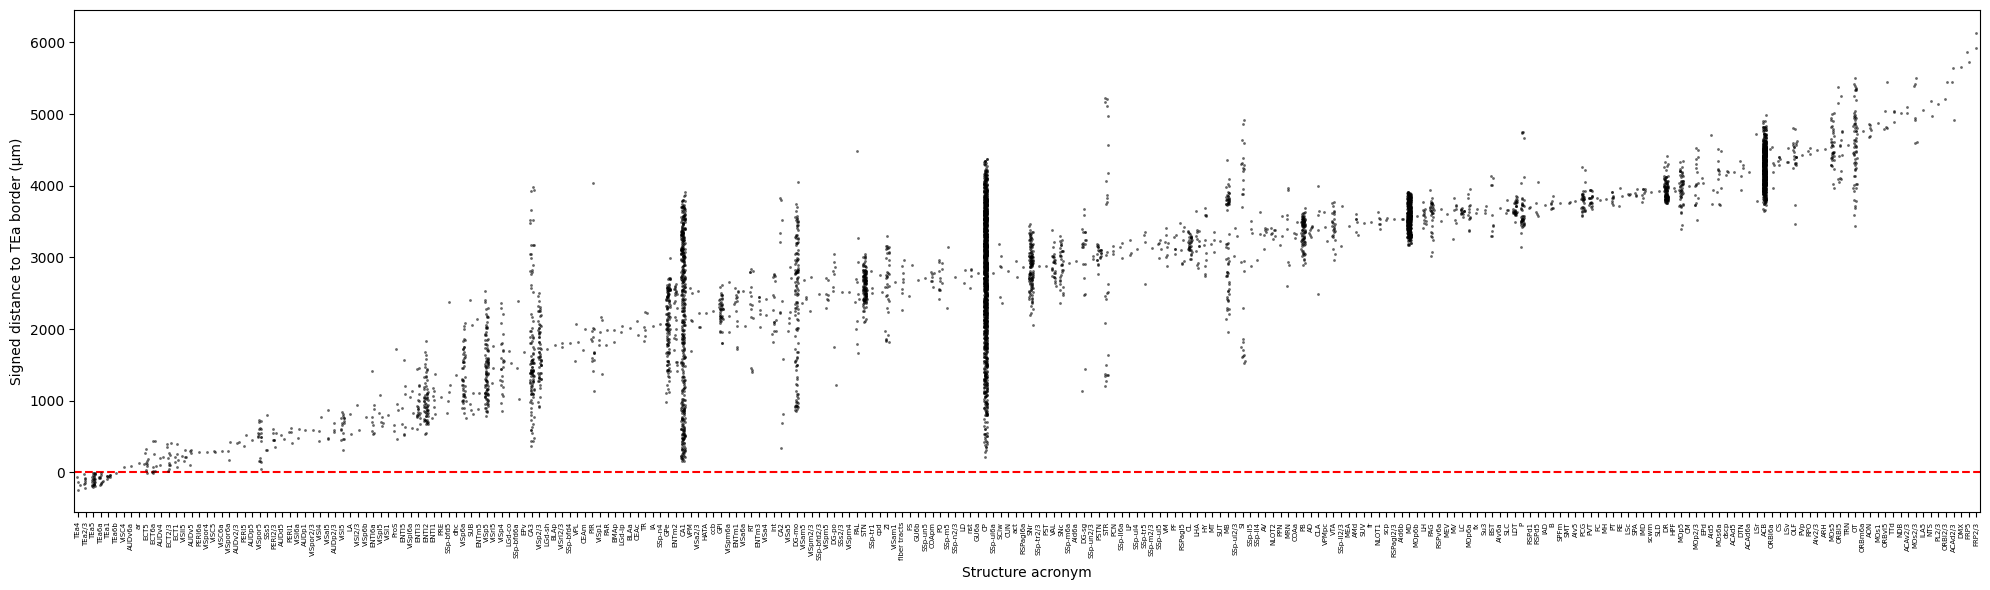

In [19]:
# Order structures from lowest to highest mean distance
structure_order = (
    soma_df.groupby('structure_acronym')['distance_to_TEa_um']
    .mean()
    .sort_values()
    .index
)

plt.figure(figsize=(20, 6))

sns.stripplot(
    data=soma_df,
    x='structure_acronym',
    y='distance_to_TEa_um',
    order=structure_order,
    jitter=0.25,
    size=2,
    alpha=0.6,
    color='black',
)

# Zero marks the TEa border
plt.axhline(0, color='red', linestyle='--', linewidth=1.5)

plt.xlabel('Structure acronym')
plt.ylabel('Signed distance to TEa border (μm)')
plt.xticks(rotation=90, fontsize=5)
plt.tight_layout()

output_path = os.path.join(output_dir, 'structure_distances_to_TEa.png')
plt.savefig(
    output_path,
    dpi=300,
    bbox_inches='tight',
    facecolor='white',
)
plt.show()

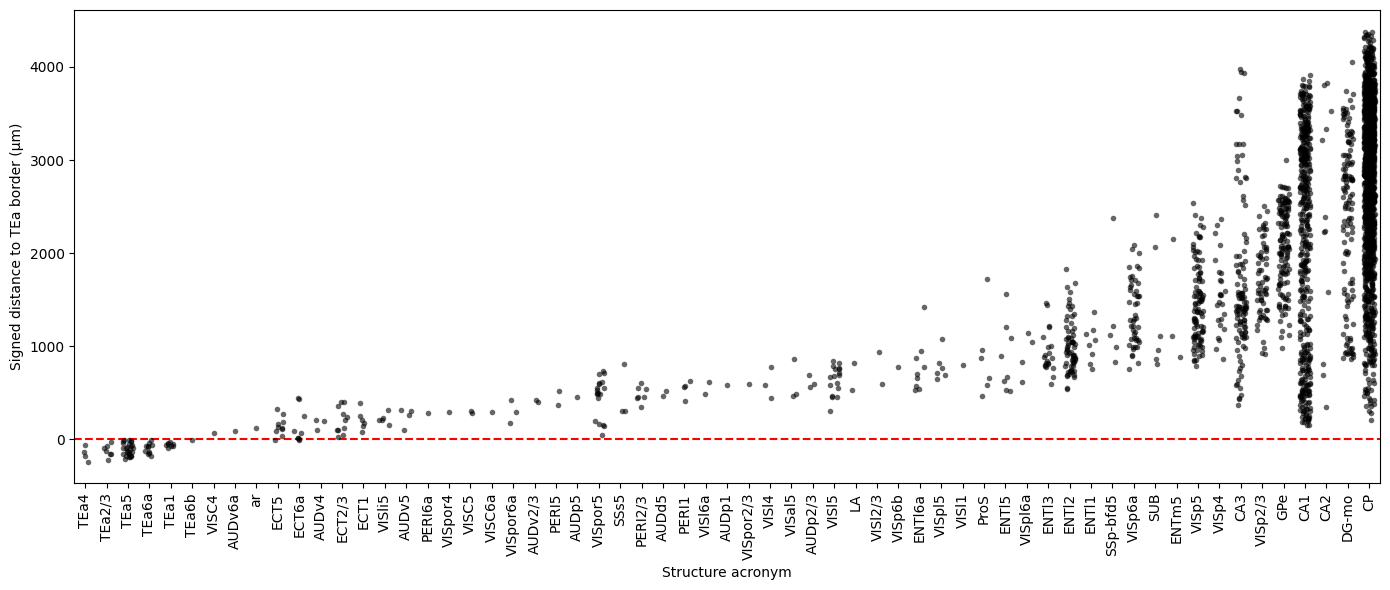

In [20]:
distance_col = 'distance_to_TEa_um'

# Structures with at least one cell within 1,000 µm of the TEa border
nearby_structures = soma_df.loc[
    soma_df[distance_col].abs() < 1000,
    'structure_acronym'
].unique()

plot_df = soma_df[
    soma_df['structure_acronym'].isin(nearby_structures)
].copy()

# Order structures by lowest to highest mean signed distance
structure_order = (
    plot_df.groupby('structure_acronym')[distance_col]
    .mean()
    .sort_values()
    .index
)

plt.figure(figsize=(14, 6))

sns.stripplot(
    data=plot_df,
    x='structure_acronym',
    y=distance_col,
    order=structure_order,
    jitter=0.25,
    size=4,
    alpha=0.6,
    color='black',
)

plt.axhline(0, color='red', linestyle='--', linewidth=1.5)
plt.xlabel('Structure acronym')
plt.ylabel('Signed distance to TEa border (μm)')
plt.xticks(rotation=90)
plt.tight_layout()

output_path = os.path.join(output_dir, 'structure_distances_to_TEa_close.png')
plt.savefig(
    output_path,
    dpi=300,
    bbox_inches='tight',
    facecolor='white',
)
plt.show()

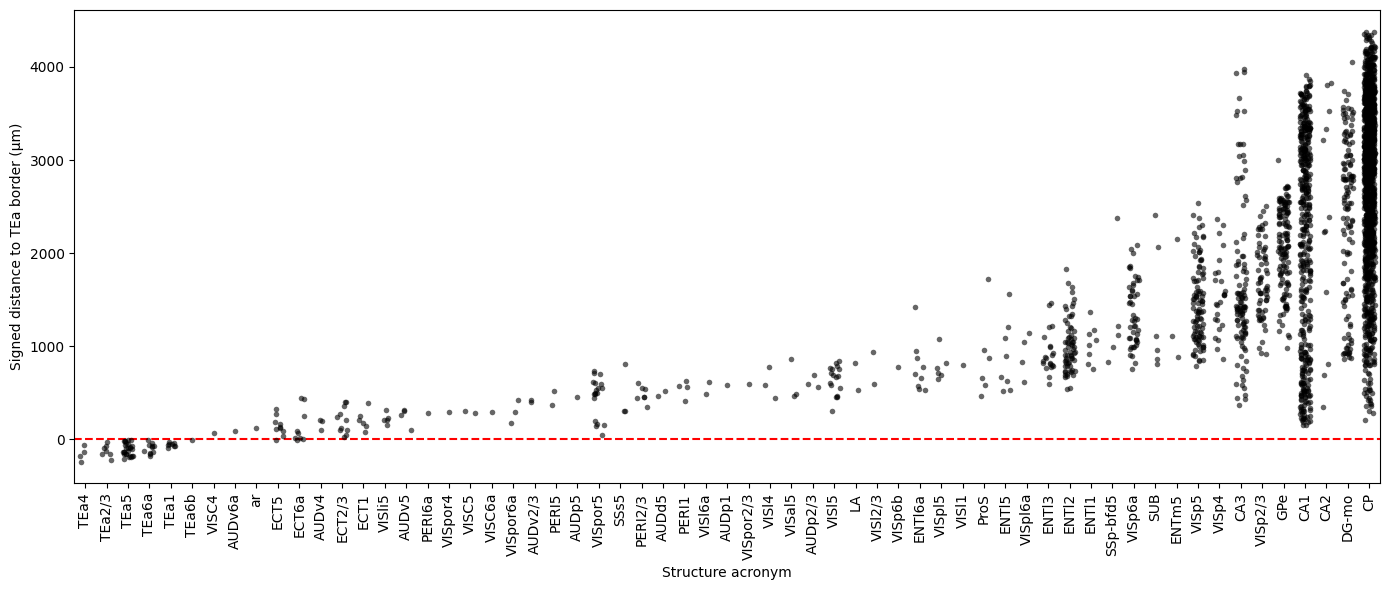

In [21]:
distance_col = 'distance_to_TEa_um'

# Structures with at least one cell within 1,000 µm of the TEa border
nearby_structures = soma_df.loc[
    soma_df[distance_col].abs() < 1000,
    'structure_acronym'
].unique()

plot_df = soma_df[
    soma_df['structure_acronym'].isin(nearby_structures)
].copy()

# Order structures by lowest to highest mean signed distance
structure_order = (
    plot_df.groupby('structure_acronym')[distance_col]
    .mean()
    .sort_values()
    .index
)

plt.figure(figsize=(14, 6))

sns.stripplot(
    data=plot_df,
    x='structure_acronym',
    y=distance_col,
    order=structure_order,
    jitter=0.25,
    size=4,
    alpha=0.6,
    color='black',
)

plt.axhline(0, color='red', linestyle='--', linewidth=1.5)
plt.xlabel('Structure acronym')
plt.ylabel('Signed distance to TEa border (μm)')
plt.xticks(rotation=90)
plt.tight_layout()

output_path = (
    '/root/capsule/scratch/20260807/mouse_TEa_distances/'
    'structure_distances_to_TEa_close.png'
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches='tight',
    facecolor='white',
)
plt.show()